In [2]:
import os, json, re
from pathlib import Path

# Find the project root (the folder containing requirements.txt), safe to re-run
ROOT = Path.cwd()
while not (ROOT / "requirements.txt").exists():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Project root (requirements.txt) not found")
    ROOT = ROOT.parent
os.chdir(ROOT)
print("Working in:", ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow.parquet as pq

TR = "data/processed/train_merged.parquet"
TE = "data/processed/test_merged.parquet"
VK = Path("src/features/v_keep_v1.json")

if not VK.exists():
    raise FileNotFoundError(f"{VK} missing: regenerate it in 01_eda (Cells 1, 12, 13, 14)")

v_keep = set(json.loads(VK.read_text())["columns"])
drop_ids = ["id_07", "id_08", "id_21", "id_22", "id_23", "id_24", "id_25", "id_26", "id_27"]

schema = pq.read_schema(TR).names
cols = [c for c in schema
        if not (re.fullmatch(r"V\d+", c) and c not in v_keep) and c not in drop_ids]

tr = pd.read_parquet(TR, columns=cols)
te = pd.read_parquet(TE, columns=[c for c in cols if c != "isFraud"])
for d in (tr, te):
    d["day"] = d["TransactionDT"] // 86400
print(f"train {tr.shape}, test {te.shape}, columns kept: {len(cols)}")

Working in: C:\Users\ASUS\OneDrive\Desktop\fraud_detection
train (590540, 226), test (506691, 225), columns kept: 225


Train days: 1 to 182
Test days:  213 to 395


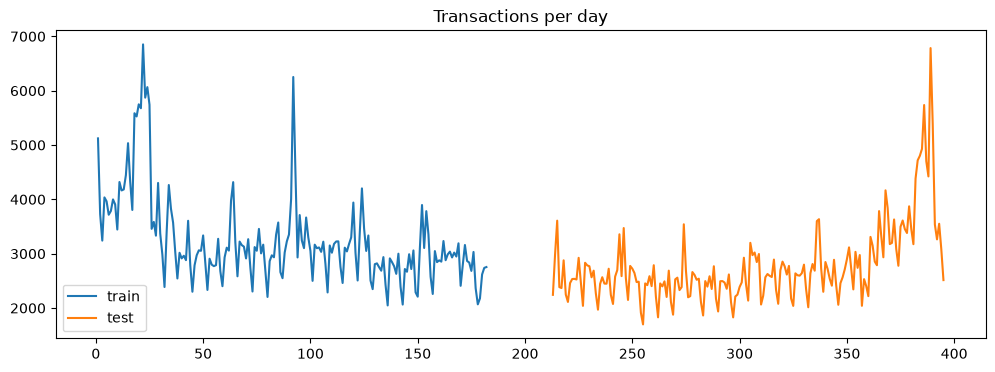

In [3]:
print(f"Train days: {tr['day'].min()} to {tr['day'].max()}")
print(f"Test days:  {te['day'].min()} to {te['day'].max()}")

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(tr.groupby("day").size(), label="train")
ax.plot(te.groupby("day").size(), label="test")
ax.set_title("Transactions per day"); ax.legend(); plt.show()

In [4]:
def shares(col):
    return pd.DataFrame({
        "train": tr[col].astype("string").fillna("NaN").value_counts(normalize=True),
        "test":  te[col].astype("string").fillna("NaN").value_counts(normalize=True),
    }).round(3)

for col in ["ProductCD", "card6", "has_identity", "DeviceType"]:
    print(f"\n=== {col} ===")
    display(shares(col))


=== ProductCD ===


,train,test
ProductCD,,
W,0.745,0.712
C,0.116,0.137
R,0.064,0.07
H,0.056,0.058
S,0.02,0.023



=== card6 ===


,train,test
card6,,
NaN,0.003,0.006
charge card,0.0,0.0
credit,0.252,0.234
debit,0.745,0.76
debit or credit,0.0,<NA>



=== has_identity ===


,train,test
has_identity,,
0,0.756,0.72
1,0.244,0.28



=== DeviceType ===


,train,test
DeviceType,,
NaN,0.762,0.73
desktop,0.144,0.147
mobile,0.094,0.123


In [5]:
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

def adv_auc(feats, n=100_000, seed=0):
    a = pd.concat([tr[feats].sample(n, random_state=seed).assign(is_test=0),
                   te[feats].sample(n, random_state=seed).assign(is_test=1)],
                  ignore_index=True)
    for c in a.select_dtypes(["object", "category"]).columns:
        a[c] = a[c].astype("category")
    X, y = a.drop(columns="is_test"), a["is_test"]
    Xtr, Xva, ytr, yva = train_test_split(X, y, test_size=0.25,
                                          random_state=seed, stratify=y)
    m = XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1,
                      tree_method="hist", enable_categorical=True, n_jobs=-1)
    m.fit(Xtr, ytr)
    auc = roc_auc_score(yva, m.predict_proba(Xva)[:, 1])
    imp = pd.Series(m.get_booster().get_score(importance_type="gain"))
    return auc, imp.sort_values(ascending=False)

base_feats = [c for c in te.columns if c not in ("TransactionID", "TransactionDT", "day")]
auc, imp = adv_auc(base_feats)
print(f"Adversarial AUC: {auc:.3f}")
display(imp.head(20).round(1))

Adversarial AUC: 0.907


V9       1954.3
id_31     511.6
V76       317.7
V336      225.1
D15       185.4
id_13     180.5
C12       138.5
M9        135.9
dist1     125.8
V325      113.1
V81        98.8
D11        90.0
V13        88.5
D10        87.8
V67        85.6
V91        85.5
V16        83.3
V36        80.7
V180       78.2
D6         73.2
dtype: float64

In [8]:
def adv_auc(feats, n=100_000, seed=0):
    a = pd.concat([tr[feats].sample(n, random_state=seed).assign(is_test=0),
                   te[feats].sample(n, random_state=seed).assign(is_test=1)],
                  ignore_index=True)
    for c in a.select_dtypes(["object", "category", "string"]).columns:
        a[c] = a[c].astype("category")
    X, y = a.drop(columns="is_test"), a["is_test"]
    Xtr, Xva, ytr, yva = train_test_split(X, y, test_size=0.25,
                                          random_state=seed, stratify=y)
    m = XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1,
                      tree_method="hist", enable_categorical=True, n_jobs=-1)
    m.fit(Xtr, ytr)
    auc = roc_auc_score(yva, m.predict_proba(Xva)[:, 1])
    imp = pd.Series(m.get_booster().get_score(importance_type="gain"))
    return auc, imp.sort_values(ascending=False)

In [9]:
for d in (tr, te):
    d["browser"] = (d["id_31"].astype("string")
                    .str.replace(r"[\d.]+", "", regex=True)
                    .str.replace(r"\s+", " ", regex=True).str.strip()
                    .astype("category"))

dcols = [f"D{i}" for i in range(1, 16)]
feats_E = [c for c in base_feats if c != "id_31"] + ["browser"]
feats_F = [c for c in feats_E if c != "V9"]
feats_G = [c for c in feats_F if c not in dcols]

for name, f in [("E: browser family instead of id_31", feats_E),
                ("F: + V9 removed", feats_F),
                ("G: + raw D columns removed", feats_G)]:
    auc_i, imp_i = adv_auc(f)
    print(f"{name}: AUC {auc_i:.3f} | top 5: {list(imp_i.head(5).index)}")

E: browser family instead of id_31: AUC 0.891 | top 5: ['V81', 'V9', 'V76', 'id_13', 'id_34']
F: + V9 removed: AUC 0.891 | top 5: ['V81', 'id_13', 'V76', 'id_34', 'V16']
G: + raw D columns removed: AUC 0.848 | top 5: ['V1', 'V81', 'V60', 'V94', 'id_13']
